In [1]:
import numpy as np
from keras.datasets import mnist

In [2]:
(X_train, _), (X_test, _) = mnist.load_data()
X_train.data

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


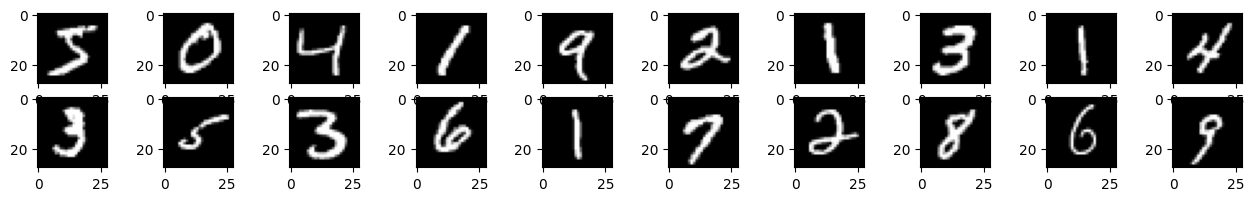

In [3]:
from matplotlib import pyplot as plt
fig, axes = plt.subplots(2, 10, figsize = (16,2))

count = 0

for i in range(2):
  for j in range(10):
    axes[i,j].imshow(X_train[count], cmap='gray')
    count+=1

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [5]:
noise_factor = 0.1
X_train_noise = X_train + noise_factor * np.random.normal(loc=0., scale =1., size = X_train.shape)
X_test_noise = X_test+ noise_factor * np.random.normal(loc=0., scale =1., size = X_test.shape)

In [6]:
X_train.shape

(60000, 28, 28)

Visualizing Noise Data

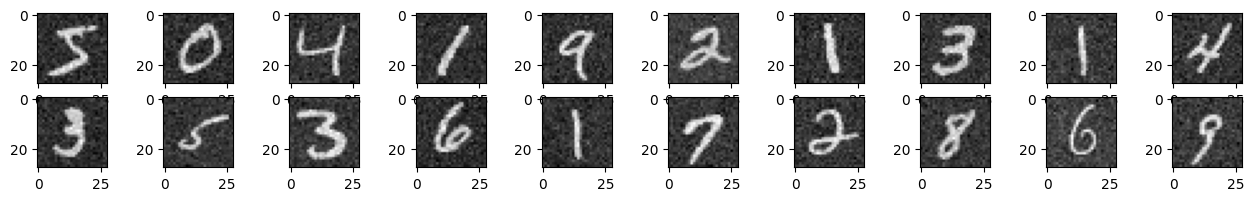

In [7]:
from matplotlib import pyplot as plt
fig, axes = plt.subplots(2, 10, figsize = (16,2))

count = 0

for i in range(2):
  for j in range(10):
    axes[i,j].imshow(X_train_noise[count], cmap='gray')
    count+=1

In [8]:
X_train = X_train.reshape(X_train.shape[0],28,28,1)
X_test = X_test.reshape(X_test.shape[0],28,28,1)

X_train_noise = X_train_noise.reshape(X_train_noise.shape[0],28,28,1)
X_test_noise = X_test_noise.reshape(X_test_noise.shape[0],28,28,1)

X_train.shape, X_train_noise.shape


((60000, 28, 28, 1), (60000, 28, 28, 1))

In [9]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPool2D, Dense, UpSampling2D, BatchNormalization
from keras.callbacks import ModelCheckpoint

import tensorflow as tf

In [10]:
devices = tf.config.experimental.list_physical_devices("GPU")
# tf.config.experimental.set_memory_growth(devices[0], enable = True)


In [11]:
encoder_input = Input(shape = X_train.shape[1:])
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(encoder_input)
x = BatchNormalization()(x)
x = MaxPool2D(pool_size = (2,2), padding = 'same')(x)
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(x)
x = BatchNormalization()(x)
encoded = MaxPool2D(pool_size = (2,2), padding = 'same')(x)

In [12]:
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(encoded)
x = BatchNormalization()(x)
x = UpSampling2D()(x)
x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(x)
x = BatchNormalization()(x)
x = UpSampling2D()(x)
decoded = Conv2D(1, (3,3), activation = 'sigmoid', padding = 'same')(x)

In [13]:
autoencoder = Model(encoder_input, decoded, name = 'Denoising_Model')
autoencoder.summary()

Model: "Denoising_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 14, 14, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 7, 7, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 7, 7, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d (UpSampling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 14, 14, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_1 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,865 (112.75 KB)

 Trainable params: 28,609 (111.75 KB)

 Non-trainable params: 256 (1.00 KB)

In [16]:
autoencoder.compile(loss = 'binary_crossentropy', optimizer = 'adam')

In [25]:
checkpoint = ModelCheckpoint("DAE.keras", save_best_only=True, save_weights_only = False, verbose = 1)
history = autoencoder.fit(X_train_noise, X_train, batch_size = 128, epochs = 50, callbacks = checkpoint, validation_split = 0.25, verbose = 2)

Epoch 1/50

Epoch 1: val_loss improved from inf to 0.07197, saving model to DAE.keras
352/352 - 106s - 302ms/step - loss: 0.0718 - val_loss: 0.0720
Epoch 2/50

Epoch 2: val_loss did not improve from 0.07197
352/352 - 144s - 408ms/step - loss: 0.0707 - val_loss: 0.0726
Epoch 3/50

Epoch 3: val_loss improved from 0.07197 to 0.07058, saving model to DAE.keras
352/352 - 142s - 404ms/step - loss: 0.0702 - val_loss: 0.0706
Epoch 4/50

Epoch 4: val_loss improved from 0.07058 to 0.06977, saving model to DAE.keras
352/352 - 142s - 403ms/step - loss: 0.0696 - val_loss: 0.0698
Epoch 5/50

Epoch 5: val_loss did not improve from 0.06977
352/352 - 142s - 404ms/step - loss: 0.0693 - val_loss: 0.0707
Epoch 6/50

Epoch 6: val_loss did not improve from 0.06977
352/352 - 145s - 412ms/step - loss: 0.0691 - val_loss: 0.0708
Epoch 7/50

Epoch 7: val_loss improved from 0.06977 to 0.06934, saving model to DAE.keras
352/352 - 108s - 308ms/step - loss: 0.0688 - val_loss: 0.0693
Epoch 8/50

Epoch 8: val_loss did

In [26]:
def visualize_data(data, row, column):
  data = data.reshape(data.shape[0],28,28)
  count = 0
  fig, axes = plt.subplots(row,column,figsize = (10,4))
  for i in range(row):
    for j in range(column):
      axes[i,j].imshow(data[count], cmap = 'gray')
      count+=1

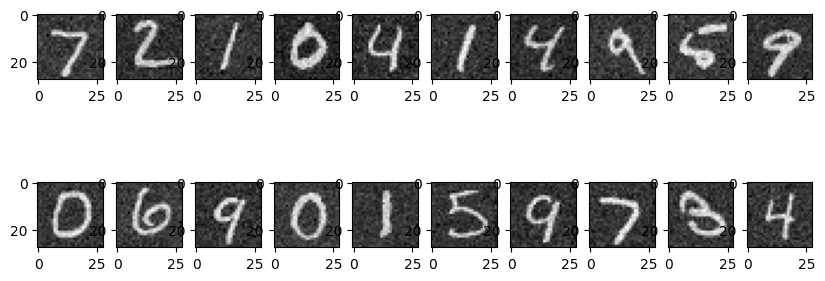

In [27]:
visualize_data(X_test_noise[:20],2,10)

In [29]:
pred = autoencoder.predict(X_test[:20])
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step


(20, 28, 28, 1)

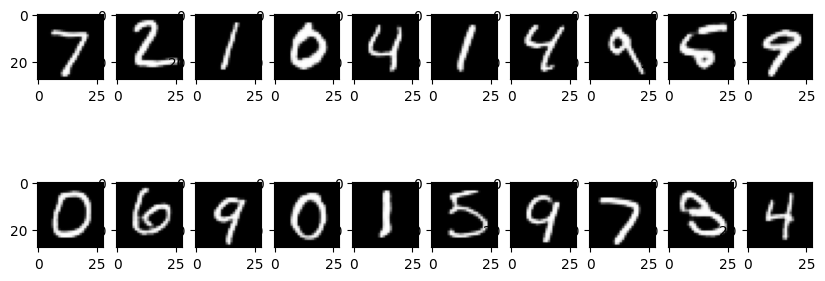

In [30]:
visualize_data(pred,2,10)